# Module 11: Single-cell RNA-seq and B-cell Classification

## Name: Jagriti Koirala
## Student ID: 1002340217

This notebook completes the Scanpy preprocessing and clustering tutorial, followed by classification of B cells versus other annotated cells.

## Preprocessing and clustering

### Setup and data retrieval

Import the analysis tools, set the figure appearance, and prepare to download the two tutorial samples.

In [1]:
%pip install -q "pandas==2.2.3" "scanpy[leiden]"

In [2]:
# Core scverse libraries
from __future__ import annotations

import anndata as ad

# Data retrieval
import pooch
import scanpy as sc

In [3]:
sc.settings.set_figure_params(dpi=50, facecolor="white")

/tmp/ipykernel_1282/2889020069.py:1: FutureWarning: Use `scanpy.set_figure_params` instead
  sc.settings.set_figure_params(dpi=50, facecolor="white")


In [4]:
EXAMPLE_DATA = pooch.create(
    path=pooch.os_cache("scverse_tutorials"),
    base_url="doi:10.6084/m9.figshare.22716739.v1/",
)
EXAMPLE_DATA.load_registry_from_doi()

In [5]:
# Download and read the two bone-marrow samples.
samples = {
    "s1d1": "s1d1_filtered_feature_bc_matrix.h5",
    "s1d3": "s1d3_filtered_feature_bc_matrix.h5",
}
adatas = {}

for sample_id, filename in samples.items():
    path = EXAMPLE_DATA.fetch(filename)
    sample_adata = sc.read_10x_h5(path)

    # Make gene names unique within each sample.
    sample_adata.var_names_make_unique()
    adatas[sample_id] = sample_adata

# Combine samples and retain the sample identity for each cell.
adata = ad.concat(adatas, label="sample")
adata.obs_names_make_unique()

# Display sample sizes and the combined data summary.
print(adata.obs["sample"].value_counts())
adata

/usr/local/lib/python3.13/dist-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


sample
s1d1    8785
s1d3    8340
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.13/dist-packages/anndata/_core/anndata.py:1882: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


AnnData object with n_obs × n_vars = 17125 × 36601
    obs: 'sample'

## Quality Control

Calculate quality measures for each cell, including the number of detected genes, total counts, and the percentage of counts from mitochondrial genes. Inspect these measures before filtering the data.

In [6]:
# Identify mitochondrial genes using the human "MT-" prefix.
adata.var["mt"] = adata.var_names.str.startswith("MT-")

# Identify ribosomal genes using the "RPS" and "RPL" prefixes.
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))

# Identify hemoglobin genes using the tutorial's naming pattern.
adata.var["hb"] = adata.var_names.str.contains("^HB[^(P)]")

# Calculate quality-control measures for cells and genes.
sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt", "ribo", "hb"],
    inplace=True,
    log1p=True,
)

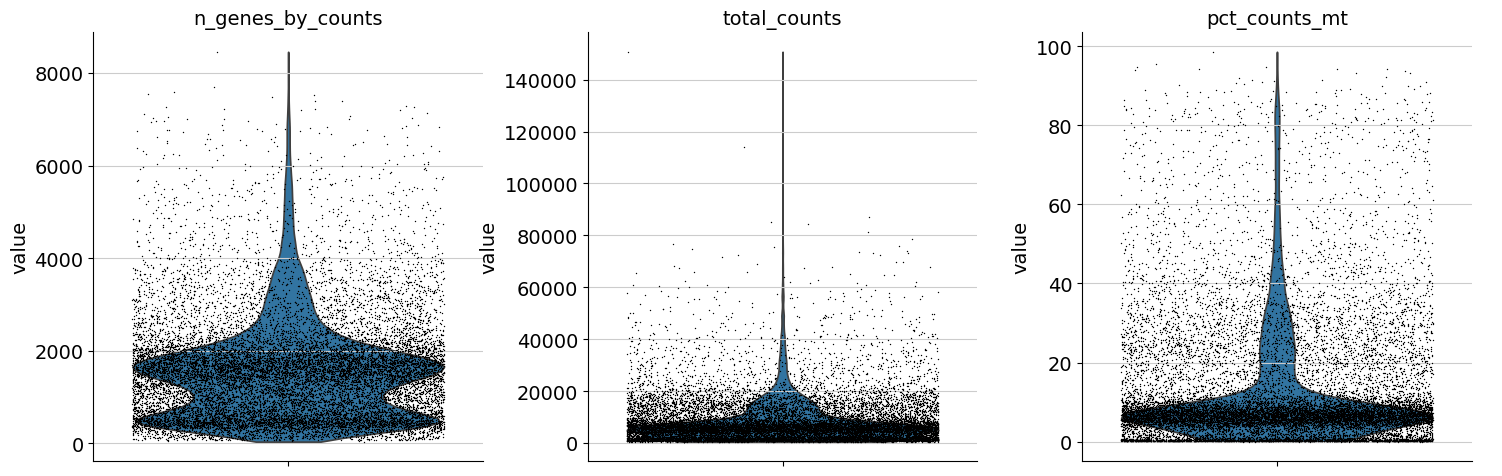

In [7]:
# Inspect detected genes, total counts, and mitochondrial percentages.
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
)

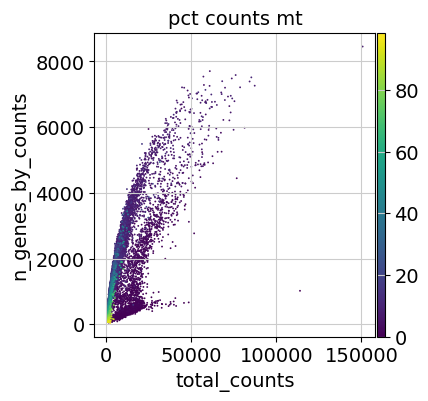

In [8]:
# Compare total counts with detected genes, colored by mitochondrial percentage.
sc.pl.scatter(
    adata,
    "total_counts",
    "n_genes_by_counts",
    color="pct_counts_mt",
)

In [9]:
# Remove cells with fewer than 100 detected genes.
sc.pp.filter_cells(adata, min_genes=100)

# Remove genes detected in fewer than 3 cells.
sc.pp.filter_genes(adata, min_cells=3)

# Display the remaining numbers of cells and genes.
print(f"After filtering: {adata.n_obs:,} cells and {adata.n_vars:,} genes")

After filtering: 17,041 cells and 23,427 genes


### Doublet detection

A doublet occurs when one captured barcode contains material from two cells. Use Scrublet separately for each sample to flag potential doublets that could affect clustering and cell-type identification.

In [10]:
# Detect potential doublets separately within each sample.
sc.pp.scrublet(adata, batch_key="sample")

## Normalization

Save the original counts, then normalize each cell to the median total count and apply a log transformation. This reduces differences caused by sequencing depth while preserving the original counts for later analysis.

In [11]:
# Preserve the original counts for later classification.
adata.layers["counts"] = adata.X.copy()

# Normalize each cell to the median total count.
sc.pp.normalize_total(adata)

# Apply the log(1 + x) transformation.
sc.pp.log1p(adata)

## Feature selection

In this step, I identify 2,000 highly variable genes while accounting for differences between samples. These genes help reveal patterns during dimensionality reduction and clustering. Later, the classifier will select genes separately using only the training data.

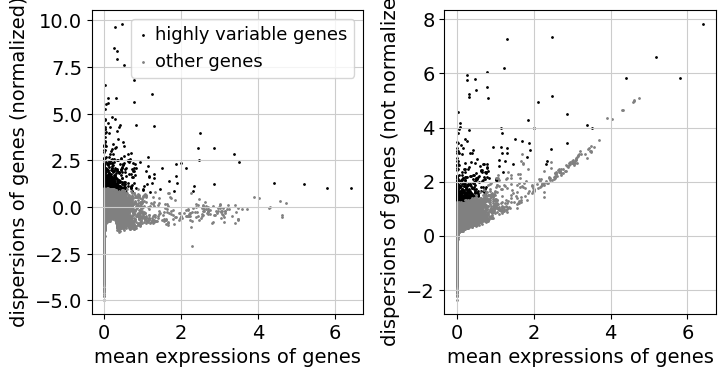

In [12]:
# Identify 2,000 highly variable genes, accounting for sample identity.
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000,
    batch_key="sample",
)

# Plot gene variability before and after normalization of dispersion.
sc.pl.highly_variable_genes(adata)

## Dimensionality Reduction

In this step, I use principal component analysis (PCA) to summarize gene-expression patterns in fewer dimensions. I then examine how much variation each principal component explains.

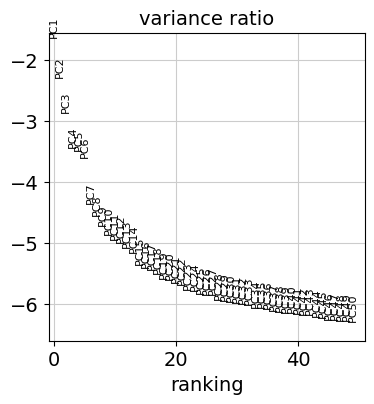

In [13]:
# Calculate principal components using the highly variable genes.
sc.tl.pca(adata)

# Show the variance explained by the first 50 principal components.
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)

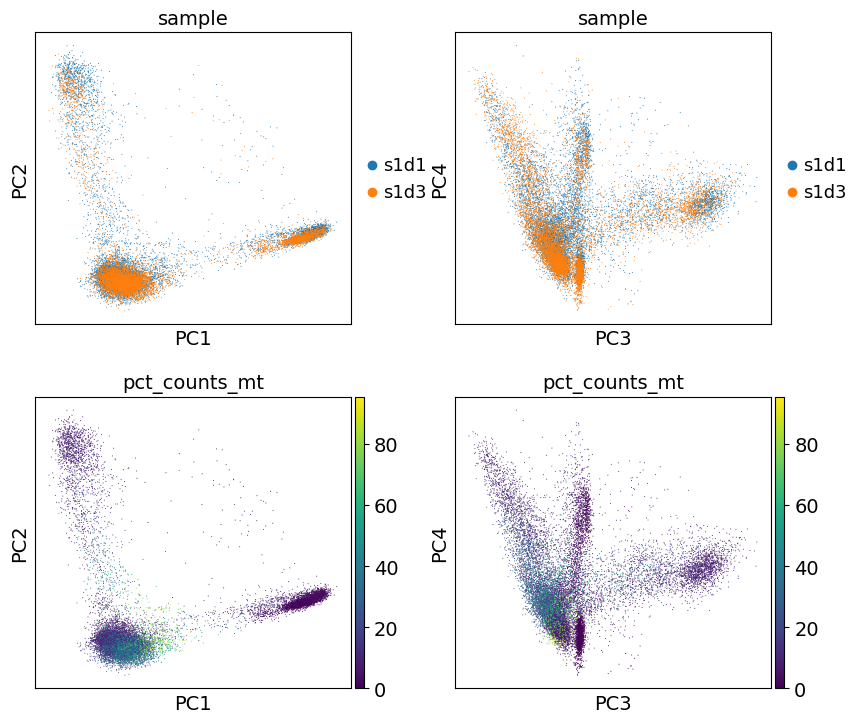

In [14]:
# Examine PCs 1–4, colored by sample and mitochondrial percentage.
sc.pl.pca(
    adata,
    color=["sample", "sample", "pct_counts_mt", "pct_counts_mt"],
    dimensions=[(0, 1), (2, 3), (0, 1), (2, 3)],
    ncols=2,
    size=2,
)

## Nearest neighbor graph construction and visualization

In this step, I connect cells with similar expression patterns using their PCA coordinates. I then use UMAP to display these relationships in two dimensions and color the cells by sample.

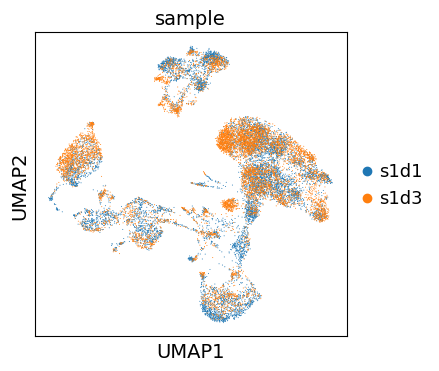

In [15]:
# Build the cell-neighbor graph using the PCA representation.
sc.pp.neighbors(adata)

# Calculate a two-dimensional UMAP representation.
sc.tl.umap(adata)

# Color cells by sample to inspect how the samples overlap.
sc.pl.umap(
    adata,
    color="sample",
    size=2,
)

## Clustering

In this step, I use Leiden clustering to group cells that are closely connected in the neighbor graph. I display the clusters on the UMAP plot. These groups still need biological interpretation before they can be assigned cell-type labels.

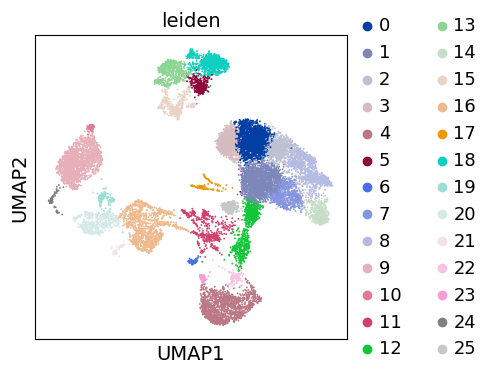

In [16]:
# Group cells using Leiden clustering on the neighbor graph.
# The igraph implementation with two iterations reduces computation time.
sc.tl.leiden(adata, flavor="igraph", n_iterations=2)

# Display the clusters on the existing UMAP coordinates.
sc.pl.umap(adata, color=["leiden"])

## Re-assess quality control and cell filtering

In this step, I compare the clusters with doublet predictions and other quality-control measures. This helps me check whether some groups might reflect doublets or poor-quality cells rather than distinct cell types.

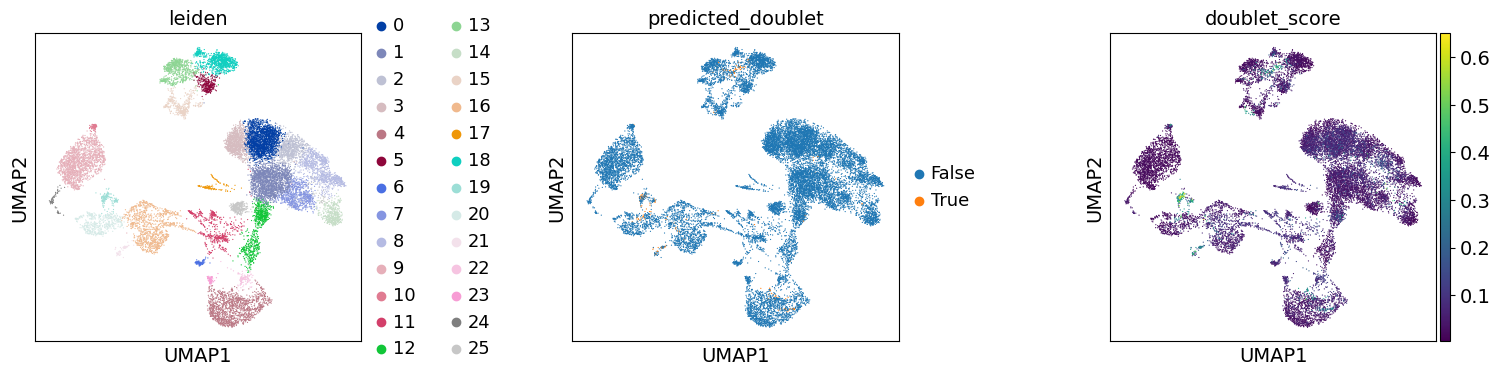

In [17]:
# Compare clusters with predicted doublets and doublet scores.
sc.pl.umap(
    adata,
    color=["leiden", "predicted_doublet", "doublet_score"],
    wspace=0.5,
    size=3,
)

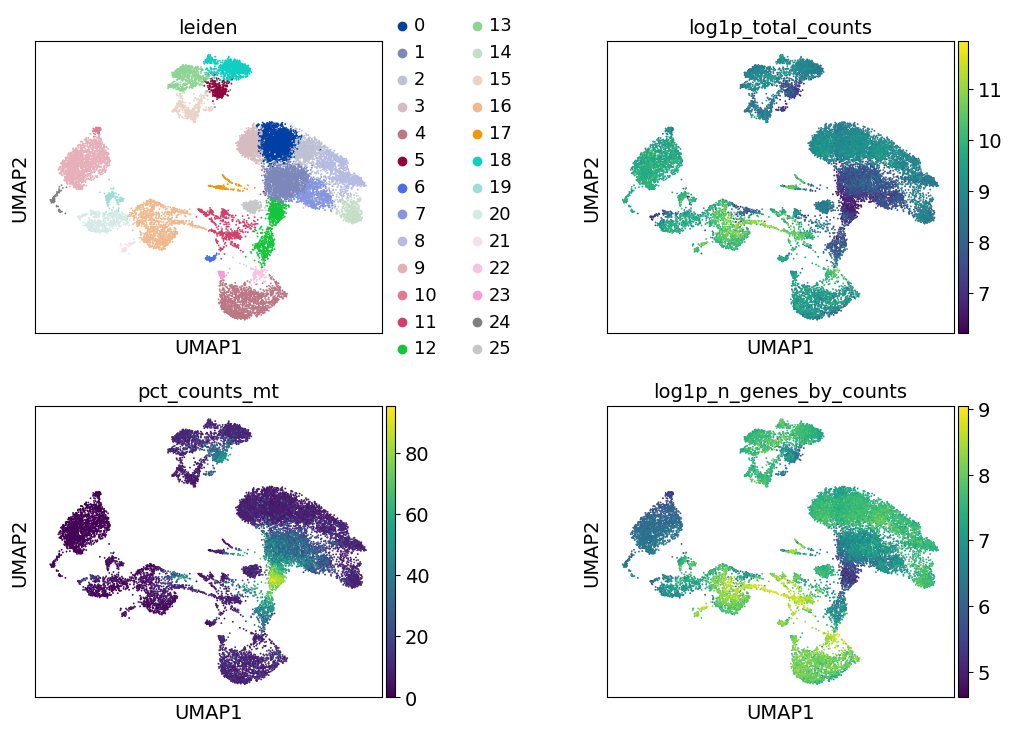

In [18]:
# Compare clusters with sequencing depth, mitochondrial percentage,
# and the number of detected genes.
sc.pl.umap(
    adata,
    color=[
        "leiden",
        "log1p_total_counts",
        "pct_counts_mt",
        "log1p_n_genes_by_counts",
    ],
    wspace=0.5,
    ncols=2,
)

## Manual cell-type annotation

In this step, I compare clustering resolutions and examine known marker genes to help identify broad cell types. These labels are interpretations based on expression patterns and biological knowledge.

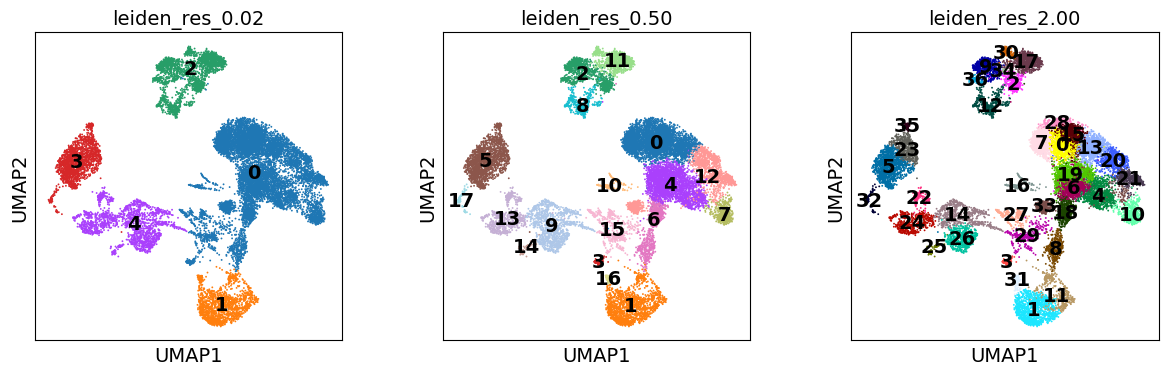

In [19]:
# Calculate Leiden clusters at three levels of detail.
for res in [0.02, 0.5, 2.0]:
    sc.tl.leiden(
        adata,
        key_added=f"leiden_res_{res:4.2f}",
        resolution=res,
        flavor="igraph",
    )

# Compare the three clustering resolutions on the same UMAP.
sc.pl.umap(
    adata,
    color=["leiden_res_0.02", "leiden_res_0.50", "leiden_res_2.00"],
    legend_loc="on data",
)

### Marker gene set

In this step, I examine known marker genes across the clusters. I use their expression patterns to help identify cell types rather than assuming that a cluster number has a fixed biological meaning.

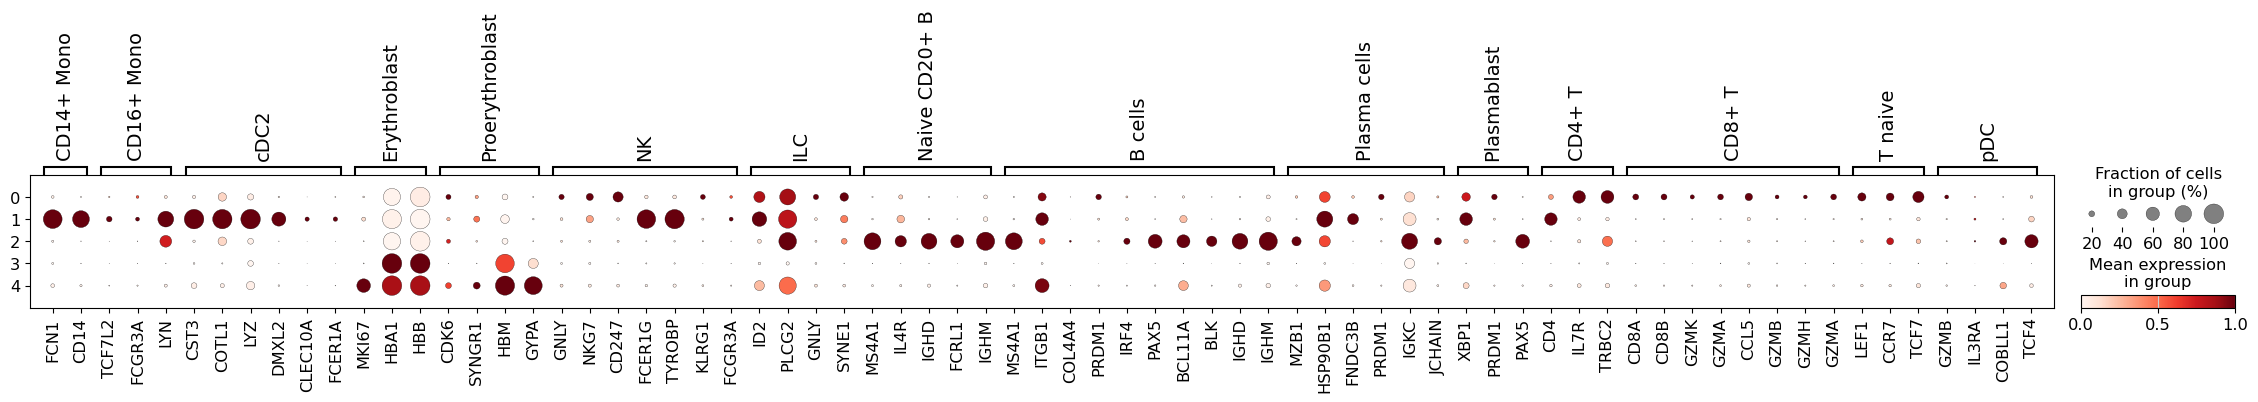

In [20]:
# Define the tutorial's marker genes for expected cell types.
# Some genes are negative markers, as noted below.
marker_genes = {
    "CD14+ Mono": ["FCN1", "CD14"],
    "CD16+ Mono": ["TCF7L2", "FCGR3A", "LYN"],
    # DMXL2 is a negative marker.
    "cDC2": ["CST3", "COTL1", "LYZ", "DMXL2", "CLEC10A", "FCER1A"],
    "Erythroblast": ["MKI67", "HBA1", "HBB"],
    # HBM and GYPA are negative markers.
    "Proerythroblast": ["CDK6", "SYNGR1", "HBM", "GYPA"],
    "NK": ["GNLY", "NKG7", "CD247", "FCER1G", "TYROBP", "KLRG1", "FCGR3A"],
    "ILC": ["ID2", "PLCG2", "GNLY", "SYNE1"],
    "Naive CD20+ B": ["MS4A1", "IL4R", "IGHD", "FCRL1", "IGHM"],
    # IGHD and IGHM are negative markers for this B-cell marker set.
    "B cells": [
        "MS4A1", "ITGB1", "COL4A4", "PRDM1", "IRF4",
        "PAX5", "BCL11A", "BLK", "IGHD", "IGHM",
    ],
    "Plasma cells": ["MZB1", "HSP90B1", "FNDC3B", "PRDM1", "IGKC", "JCHAIN"],
    # PAX5 is a negative marker.
    "Plasmablast": ["XBP1", "PRDM1", "PAX5"],
    "CD4+ T": ["CD4", "IL7R", "TRBC2"],
    "CD8+ T": ["CD8A", "CD8B", "GZMK", "GZMA", "CCL5", "GZMB", "GZMH", "GZMA"],
    "T naive": ["LEF1", "CCR7", "TCF7"],
    "pDC": ["GZMB", "IL3RA", "COBLL1", "TCF4"],
}

# Compare marker expression across the lowest-resolution clusters.
sc.pl.dotplot(
    adata,
    marker_genes,
    groupby="leiden_res_0.02",
    standard_scale="var",
)

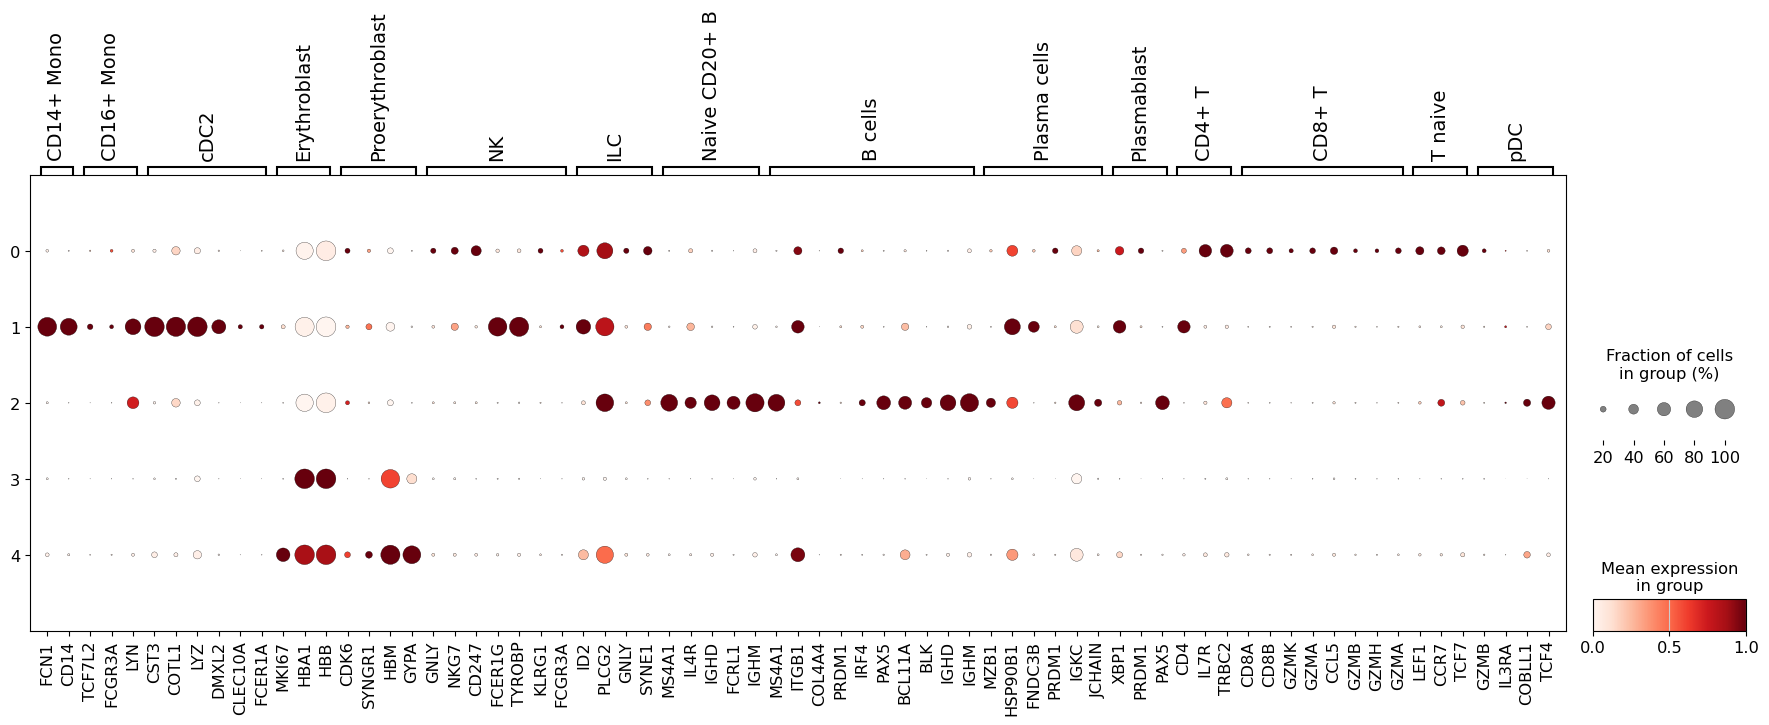

In [21]:
# Enlarge the marker plot so cluster labels and genes are readable.
sc.pl.dotplot(
    adata,
    marker_genes,
    groupby="leiden_res_0.02",
    standard_scale="var",
    figsize=(22, 6),
)

In [22]:
# Assign broad cell-type labels based on the observed marker patterns.
# Cluster numbers differ from those in the tutorial example.
adata.obs["cell_type_lvl1"] = adata.obs["leiden_res_0.02"].map(
    {
        "0": "Lymphocytes",
        "1": "Monocytes",
        "2": "B Cells",
        "3": "Erythroid",
        "4": "Erythroid",
    }
)

# Check how many cells received each label.
print(adata.obs["cell_type_lvl1"].value_counts())

# Confirm that every cell has an annotation.
print("Cells without a label:", adata.obs["cell_type_lvl1"].isna().sum())

cell_type_lvl1
Lymphocytes    9763
Erythroid      3502
B Cells        2269
Monocytes      1507
Name: count, dtype: int64
Cells without a label: 0


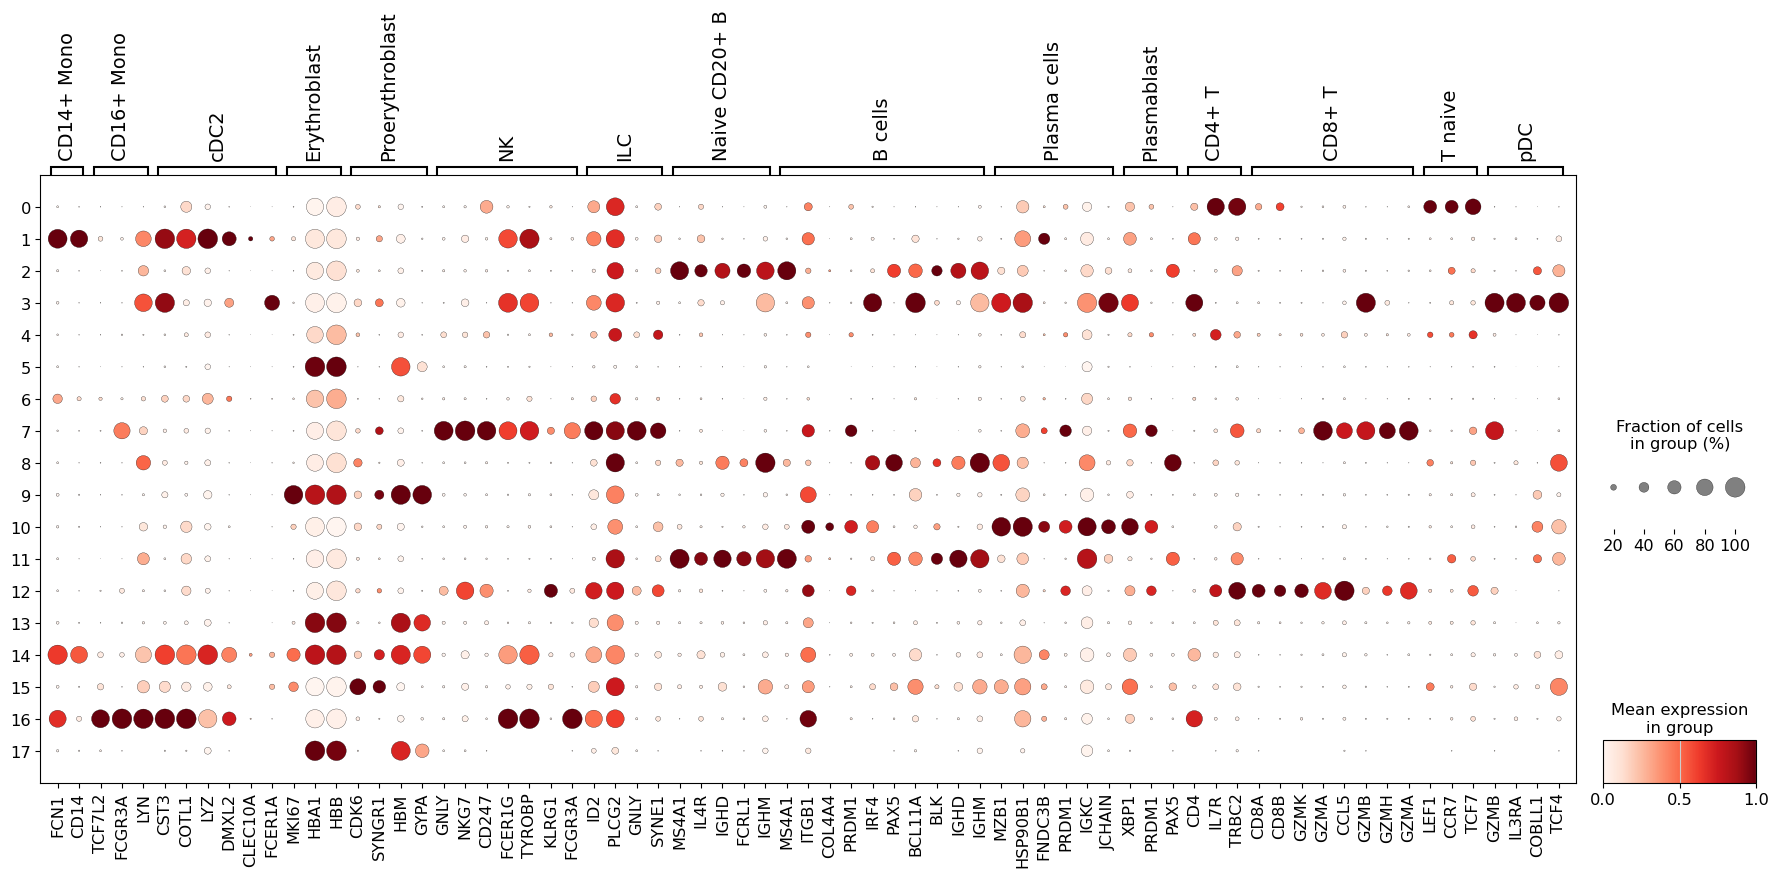

In [23]:
# Examine marker expression at the intermediate clustering resolution.
sc.pl.dotplot(
    adata,
    marker_genes,
    groupby="leiden_res_0.50",
    standard_scale="var",
    figsize=(22, 8),
)

### Differentially-expressed Genes as Markers

In this step, I identify genes expressed differently in each cluster compared with the remaining cells. These genes can help interpret the clusters, but differences in expression alone do not prove a gene’s function or a cell’s identity.

In [24]:
# Identify genes expressed differently in each cluster versus all other cells.
sc.tl.rank_genes_groups(
    adata,
    groupby="leiden_res_0.50",
    method="wilcoxon",
)

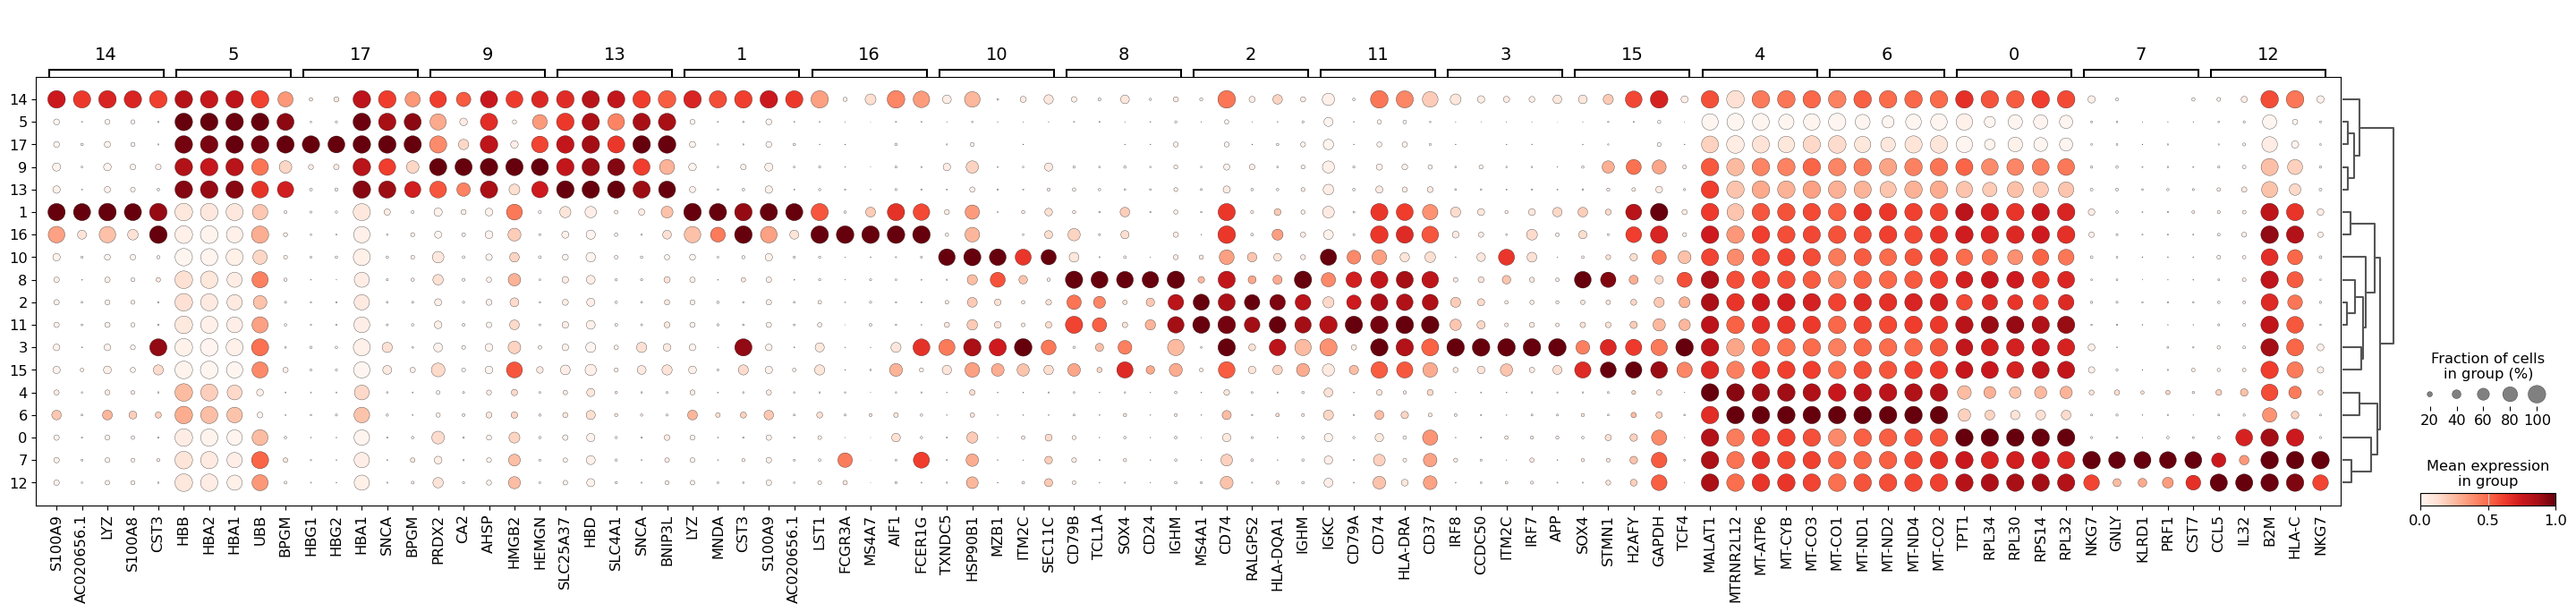

In [25]:
# Display the top five differentially expressed genes for each cluster.
sc.pl.rank_genes_groups_dotplot(
    adata,
    groupby="leiden_res_0.50",
    standard_scale="var",
    n_genes=5,
)

In [26]:
# Display the five highest-ranked marker genes for cluster 7.
sc.get.rank_genes_groups_df(adata, group="7").head(5)

,names,scores,logfoldchanges,pvals,pvals_adj
0,NKG7,35.537918,6.548978,1.277051e-276,2.991748e-272
1,GNLY,33.851448,7.374753,3.455431e-251,4.047519e-247
2,KLRD1,33.814442,5.832656,1.209767e-250,9.447073e-247
3,PRF1,33.023769,5.431675,3.703158e-239,2.168847e-235
4,CST7,33.007786,5.233107,6.280117e-239,2.942486e-235


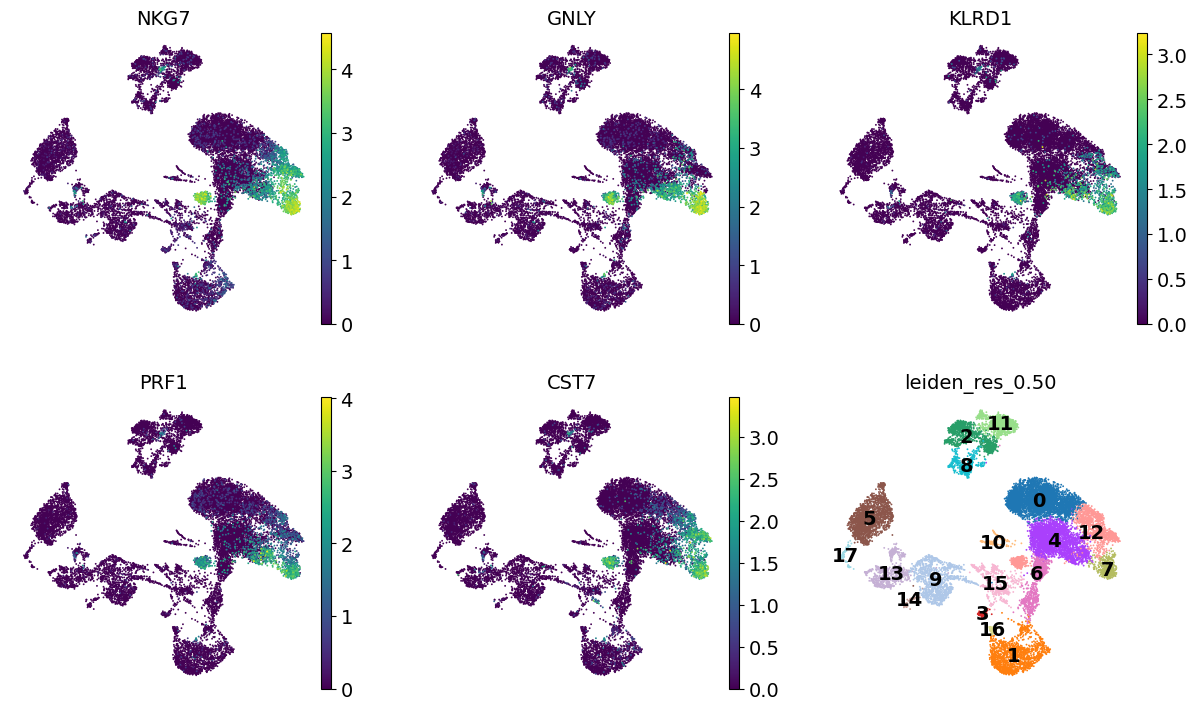

In [27]:
# Get cluster 7's top five marker genes.
cluster7_genes = sc.get.rank_genes_groups_df(
    adata,
    group="7",
).head(5)["names"]

# Compare marker expression with the cluster locations.
sc.pl.umap(
    adata,
    color=[*cluster7_genes, "leiden_res_0.50"],
    legend_loc="on data",
    frameon=False,
    ncols=3,
)

## B-cell classification

In this section, I compare logistic regression, Random Forest, and RBF SVM classifiers to predict B cells versus other annotated cells. I use training data for gene selection and hyperparameter tuning, validation data to choose the classifier, and test data for the final evaluation. The target labels come from the tutorial’s cluster annotations, so agreement with those labels does not independently establish biological identity.

### Cell 1: Import tools and define settings

I import the classification tools and define the positive label, number of selected genes, and random seed.

In [28]:
# Import tools for preparing data, training models, and evaluating predictions.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import sparse
from IPython.display import display

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV
)
from sklearn.preprocessing import normalize, StandardScaler
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    RocCurveDisplay,
    ConfusionMatrixDisplay,
    classification_report,
)

# Define the target labels and reproducible analysis settings.
SEED = 42
LABEL_COLUMN = "cell_type_lvl1"
POSITIVE_LABEL = "B Cells"
N_GENES = 500
N_JOBS = 2

### Cell 2: Prepare expression data and split the cells

In this step, I label B cells as 1 and other annotated cells as 0. I prepare a separate normalized expression matrix from the saved counts and divide the cells into 60% training, 20% validation, and 20% test sets. Stratification keeps the B-cell proportions similar across the three sets.

In [29]:
# Confirm that the tutorial's annotations and original counts are available.
if LABEL_COLUMN not in adata.obs:
    raise ValueError("Run the tutorial's cell-type annotation cell first.")

if "counts" not in adata.layers:
    raise ValueError("The tutorial's saved counts layer is missing.")

# Keep cells with annotations and check that the B-cell label exists.
keep = adata.obs[LABEL_COLUMN].notna().to_numpy()
labels = adata.obs.loc[keep, LABEL_COLUMN].astype(str)

if POSITIVE_LABEL not in labels.unique():
    raise ValueError(
        f"{POSITIVE_LABEL!r} was not found. "
        f"Available labels: {sorted(labels.unique())}"
    )

# Assign B Cells = 1 and other annotated cells = 0.
y = (labels == POSITIVE_LABEL).to_numpy(dtype=int)
cell_indices = np.flatnonzero(keep)

# Copy the original counts without changing adata.
X = sparse.csr_matrix(
    adata.layers["counts"][keep], dtype=np.float64
).copy()

if not np.isfinite(X.data).all() or (X.data < 0).any():
    raise ValueError("Expected finite, nonnegative counts.")

if np.any(np.asarray(X.sum(axis=1)).ravel() == 0):
    raise ValueError("Found cells with zero total counts.")

# Normalize each cell independently to 10,000 counts and log-transform.
X = normalize(X, norm="l1", axis=1) * 10_000
X.data = np.log1p(X.data)
X = X.tocsr()

# Reserve 20% of cells for the final test set.
indices = np.arange(len(y))
trainval_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    stratify=y,
    random_state=SEED,
)

# Use 25% of the remaining 80% for validation: 20% of all cells.
train_idx, val_idx = train_test_split(
    trainval_idx,
    test_size=0.25,
    stratify=y[trainval_idx],
    random_state=SEED,
)

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

# Check that each training class has enough cells for five-fold CV.
if np.bincount(y_train, minlength=2).min() < 5:
    raise ValueError(
        "Five-fold CV requires at least five training cells per class."
    )

# Summarize partition sizes and class proportions.
summary = pd.DataFrame([
    {
        "Partition": name,
        "Cells": len(target),
        "B Cells": int(target.sum()),
        "Other cells": int((target == 0).sum()),
        "B-cell fraction": target.mean(),
    }
    for name, target in [
        ("Training", y_train),
        ("Validation", y_val),
        ("Test", y_test),
    ]
])

display(summary.round(3))
print("Positive class: B Cells (1)")
print("Negative class: other annotated cells (0)")
print("Expression matrix:", X.shape)

,Partition,Cells,B Cells,Other cells,B-cell fraction
0,Training,10224,1361,8863,0.133
1,Validation,3408,454,2954,0.133
2,Test,3409,454,2955,0.133


Positive class: B Cells (1)
Negative class: other annotated cells (0)
Expression matrix: (17041, 23427)


### Cell 3: Define pipelines and search grids

In this step, I define the three classifiers and the hyperparameter settings to compare. Each pipeline removes constant genes and selects 500 genes using the training labels. Logistic regression and SVM also scale the selected features. Keeping these steps inside the pipeline ensures they are fitted separately within each training fold.

In [30]:
# Keep gene selection and scaling inside each training fold.
def make_classifier_pipeline(classifier, scale=False):
    steps = [
        ("remove_constant", VarianceThreshold()),
        ("select_genes", SelectKBest(score_func=f_classif, k=N_GENES)),
    ]

    if scale:
        steps.append(("scale", StandardScaler(with_mean=False)))

    steps.append(("classifier", classifier))
    return Pipeline(steps)


# Define each classifier and its hyperparameter search grid.
model_specs = {
    "Logistic regression": (
        make_classifier_pipeline(
            LogisticRegression(
                solver="liblinear",
                max_iter=5000,
                random_state=SEED,
            ),
            scale=True,
        ),
        {
            "classifier__C": [0.01, 0.1, 1.0],
        },
    ),

    "Random forest": (
        make_classifier_pipeline(
            RandomForestClassifier(
                n_estimators=200,
                random_state=SEED,
                n_jobs=1,
            )
        ),
        {
            "classifier__max_depth": [10, None],
            "classifier__min_samples_leaf": [1, 5],
        },
    ),

    "RBF SVM": (
        make_classifier_pipeline(
            SVC(
                kernel="rbf",
                probability=False,
                cache_size=300,
                random_state=SEED,
            ),
            scale=True,
        ),
        {
            "classifier__C": [0.1, 1.0],
            "classifier__gamma": ["scale", 0.001],
        },
    ),
}

# Preserve class proportions within each cross-validation fold.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED,
)

### Cell 4: Run five-fold grid search and choose the classifier

In this step, I use five-fold cross-validation within the training set to select hyperparameters for each classifier. I then compare the three fitted models using validation average precision and select the highest-scoring model. The test set is not used to make these choices.

In [31]:
# Return continuous scores for the positive class: B Cells (1).
def positive_scores(model, features):
    if hasattr(model, "predict_proba"):
        positive_column = np.flatnonzero(model.classes_ == 1)[0]
        return model.predict_proba(features)[:, positive_column]

    if not np.array_equal(model.classes_, np.array([0, 1])):
        raise ValueError("Expected binary classes [0, 1].")

    return model.decision_function(features)


searches = {}
validation_scores = {}
comparison_rows = []

# Tune each classifier using training data only.
for name, (pipeline, grid) in model_specs.items():
    print(f"\nRunning five-fold grid search: {name}")

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=grid,
        scoring="average_precision",
        cv=cv,
        refit=True,
        n_jobs=N_JOBS,
        pre_dispatch=N_JOBS,
        return_train_score=False,
        error_score="raise",
        verbose=1,
    )

    search.fit(X_train, y_train)
    searches[name] = search

    # Compare each family's best model on validation data.
    scores = positive_scores(search.best_estimator_, X_val)
    validation_scores[name] = scores

    comparison_rows.append({
        "Classifier": name,
        "CV average precision": search.best_score_,
        "CV AP SD": search.cv_results_["std_test_score"][search.best_index_],
        "Validation average precision": average_precision_score(y_val, scores),
        "Validation ROC-AUC": roc_auc_score(y_val, scores),
        "Best parameters": search.best_params_,
    })

# Rank models by validation average precision.
comparison = (
    pd.DataFrame(comparison_rows)
    .set_index("Classifier")
    .sort_values(
        "Validation average precision",
        ascending=False,
        kind="stable",
    )
)

display(comparison.round(4))

# Lock the winning model without consulting the test results.
winner_name = comparison.index[0]
winner_model = searches[winner_name].best_estimator_

print(f"\nSelected classifier: {winner_name}")
print("Selection criterion: highest validation average precision")
print("The test set has not been used for model selection.")


Running five-fold grid search: Logistic regression
Fitting 5 folds for each of 3 candidates, totalling 15 fits

Running five-fold grid search: Random forest
Fitting 5 folds for each of 4 candidates, totalling 20 fits

Running five-fold grid search: RBF SVM
Fitting 5 folds for each of 4 candidates, totalling 20 fits


,CV average precision,CV AP SD,Validation average precision,Validation ROC-AUC,Best parameters
Classifier,,,,,
RBF SVM,0.9988,0.0008,0.9986,0.9998,"{'classifier__C': 1.0, 'classifier__gamma': 0...."
Random forest,0.9985,0.0008,0.9977,0.9997,"{'classifier__max_depth': None, 'classifier__m..."
Logistic regression,0.9981,0.0013,0.9972,0.9996,{'classifier__C': 0.1}



Selected classifier: RBF SVM
Selection criterion: highest validation average precision
The test set has not been used for model selection.


In [32]:
# Display the selected model's complete hyperparameters.
print("Selected classifier:", winner_name)
print("Best hyperparameters:", searches[winner_name].best_params_)

Selected classifier: RBF SVM
Best hyperparameters: {'classifier__C': 1.0, 'classifier__gamma': 0.001}


### Cell 5: Compare validation ROC curves

In this step, I compare the validation ROC curves for the best model from each classifier family. ROC-AUC summarizes how well each model ranks B cells above other cells. These curves describe performance, but the selected classifier remains the one with the highest validation average precision.

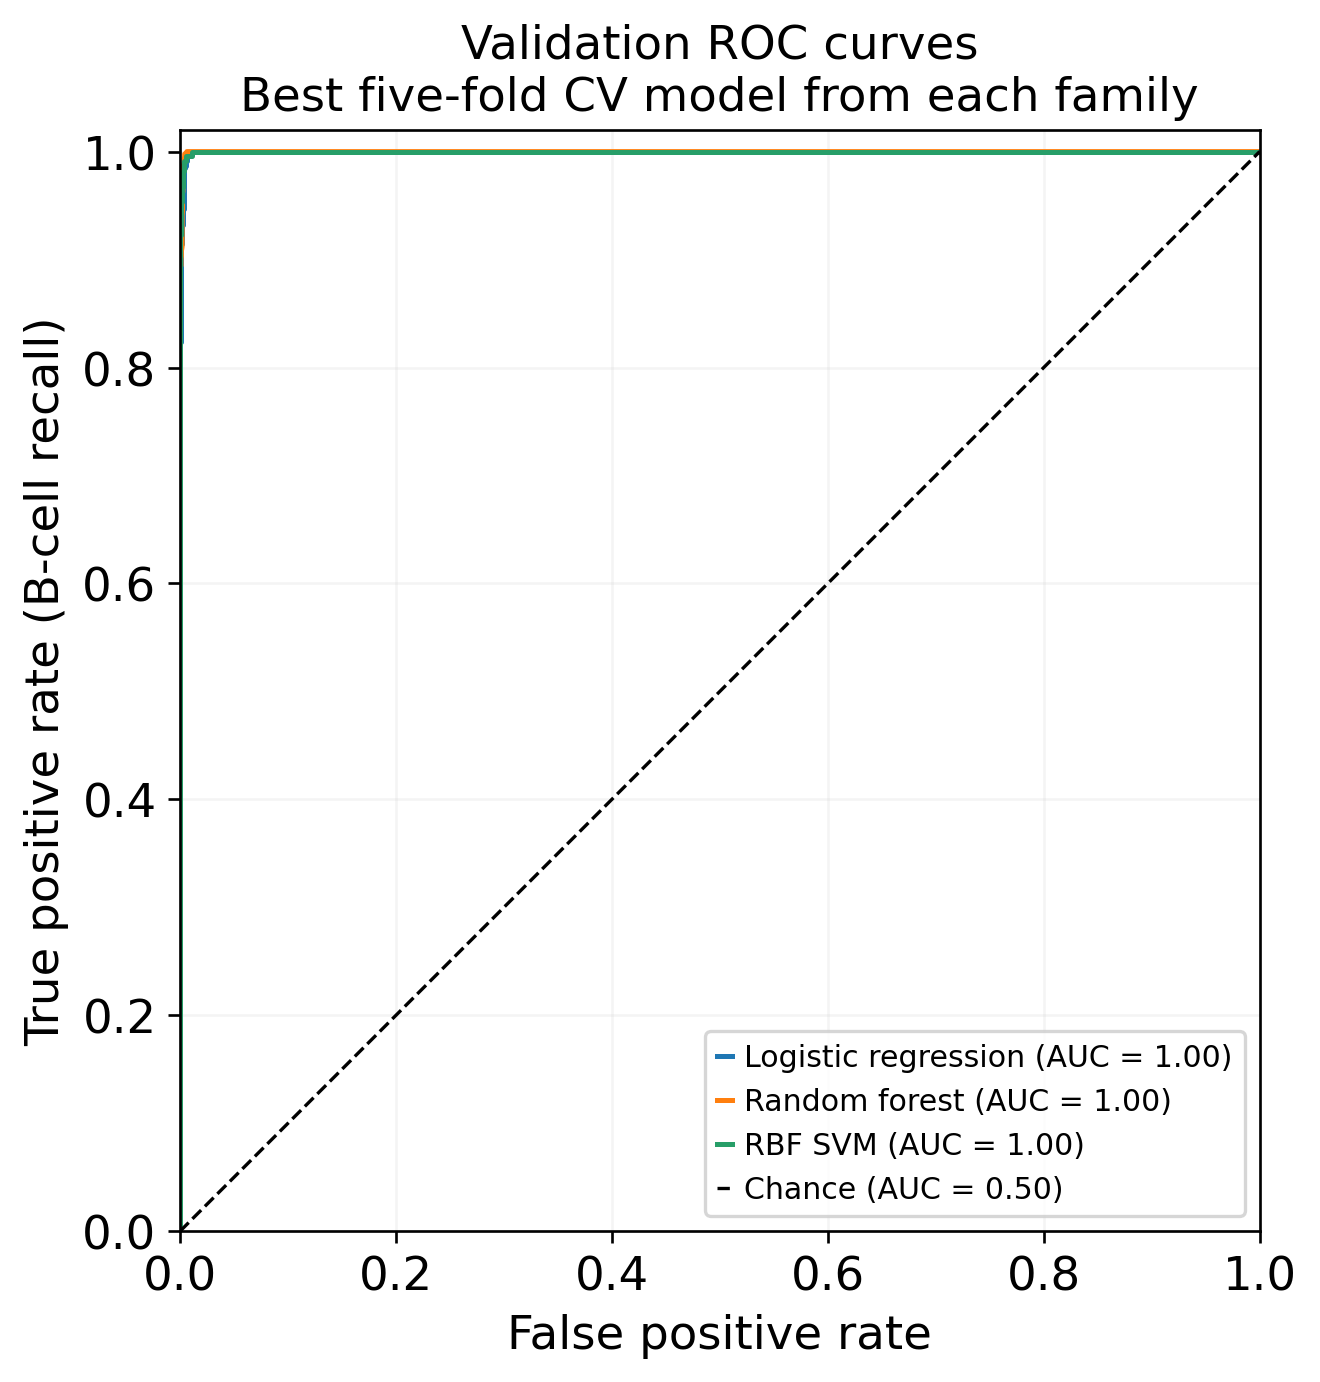

Winner by validation average precision: RBF SVM
ROC-AUC is displayed for comparison; it did not choose the winner.


In [33]:
# Plot validation ROC curves for each classifier family's best model.
fig, ax = plt.subplots(figsize=(7, 6), dpi=120)

for name, scores in validation_scores.items():
    RocCurveDisplay.from_predictions(
        y_val,
        scores,
        name=name,
        ax=ax,
    )

# Add the chance-level reference line.
ax.plot(
    [0, 1], [0, 1],
    "k--",
    linewidth=1,
    label="Chance (AUC = 0.50)",
)

ax.set(
    title="Validation ROC curves\nBest five-fold CV model from each family",
    xlabel="False positive rate",
    ylabel="True positive rate (B-cell recall)",
    xlim=(0, 1),
    ylim=(0, 1.02),
)
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Confirm that average precision, not ROC-AUC, selected the winner.
print(
    f"Winner by validation average precision: {winner_name}\n"
    "ROC-AUC is displayed for comparison; it did not choose the winner."
)

### Cell 6: Evaluate the winner on the test set

In this step, I evaluate the selected RBF SVM on the test set without further tuning or refitting. I report average precision, ROC-AUC, and classification metrics, then examine the ROC curve and confusion matrix. The confusion matrix uses the model’s default decision rule.

Final test evaluation: RBF SVM
Test average precision: 0.9978
Test ROC-AUC:           0.9997
Test B-cell prevalence: 0.1332

Classification report at the model's default threshold:

                       precision    recall  f1-score   support

Other annotated cells      0.997     0.995     0.996      2955
              B Cells      0.967     0.982     0.975       454

             accuracy                          0.993      3409
            macro avg      0.982     0.989     0.985      3409
         weighted avg      0.993     0.993     0.993      3409



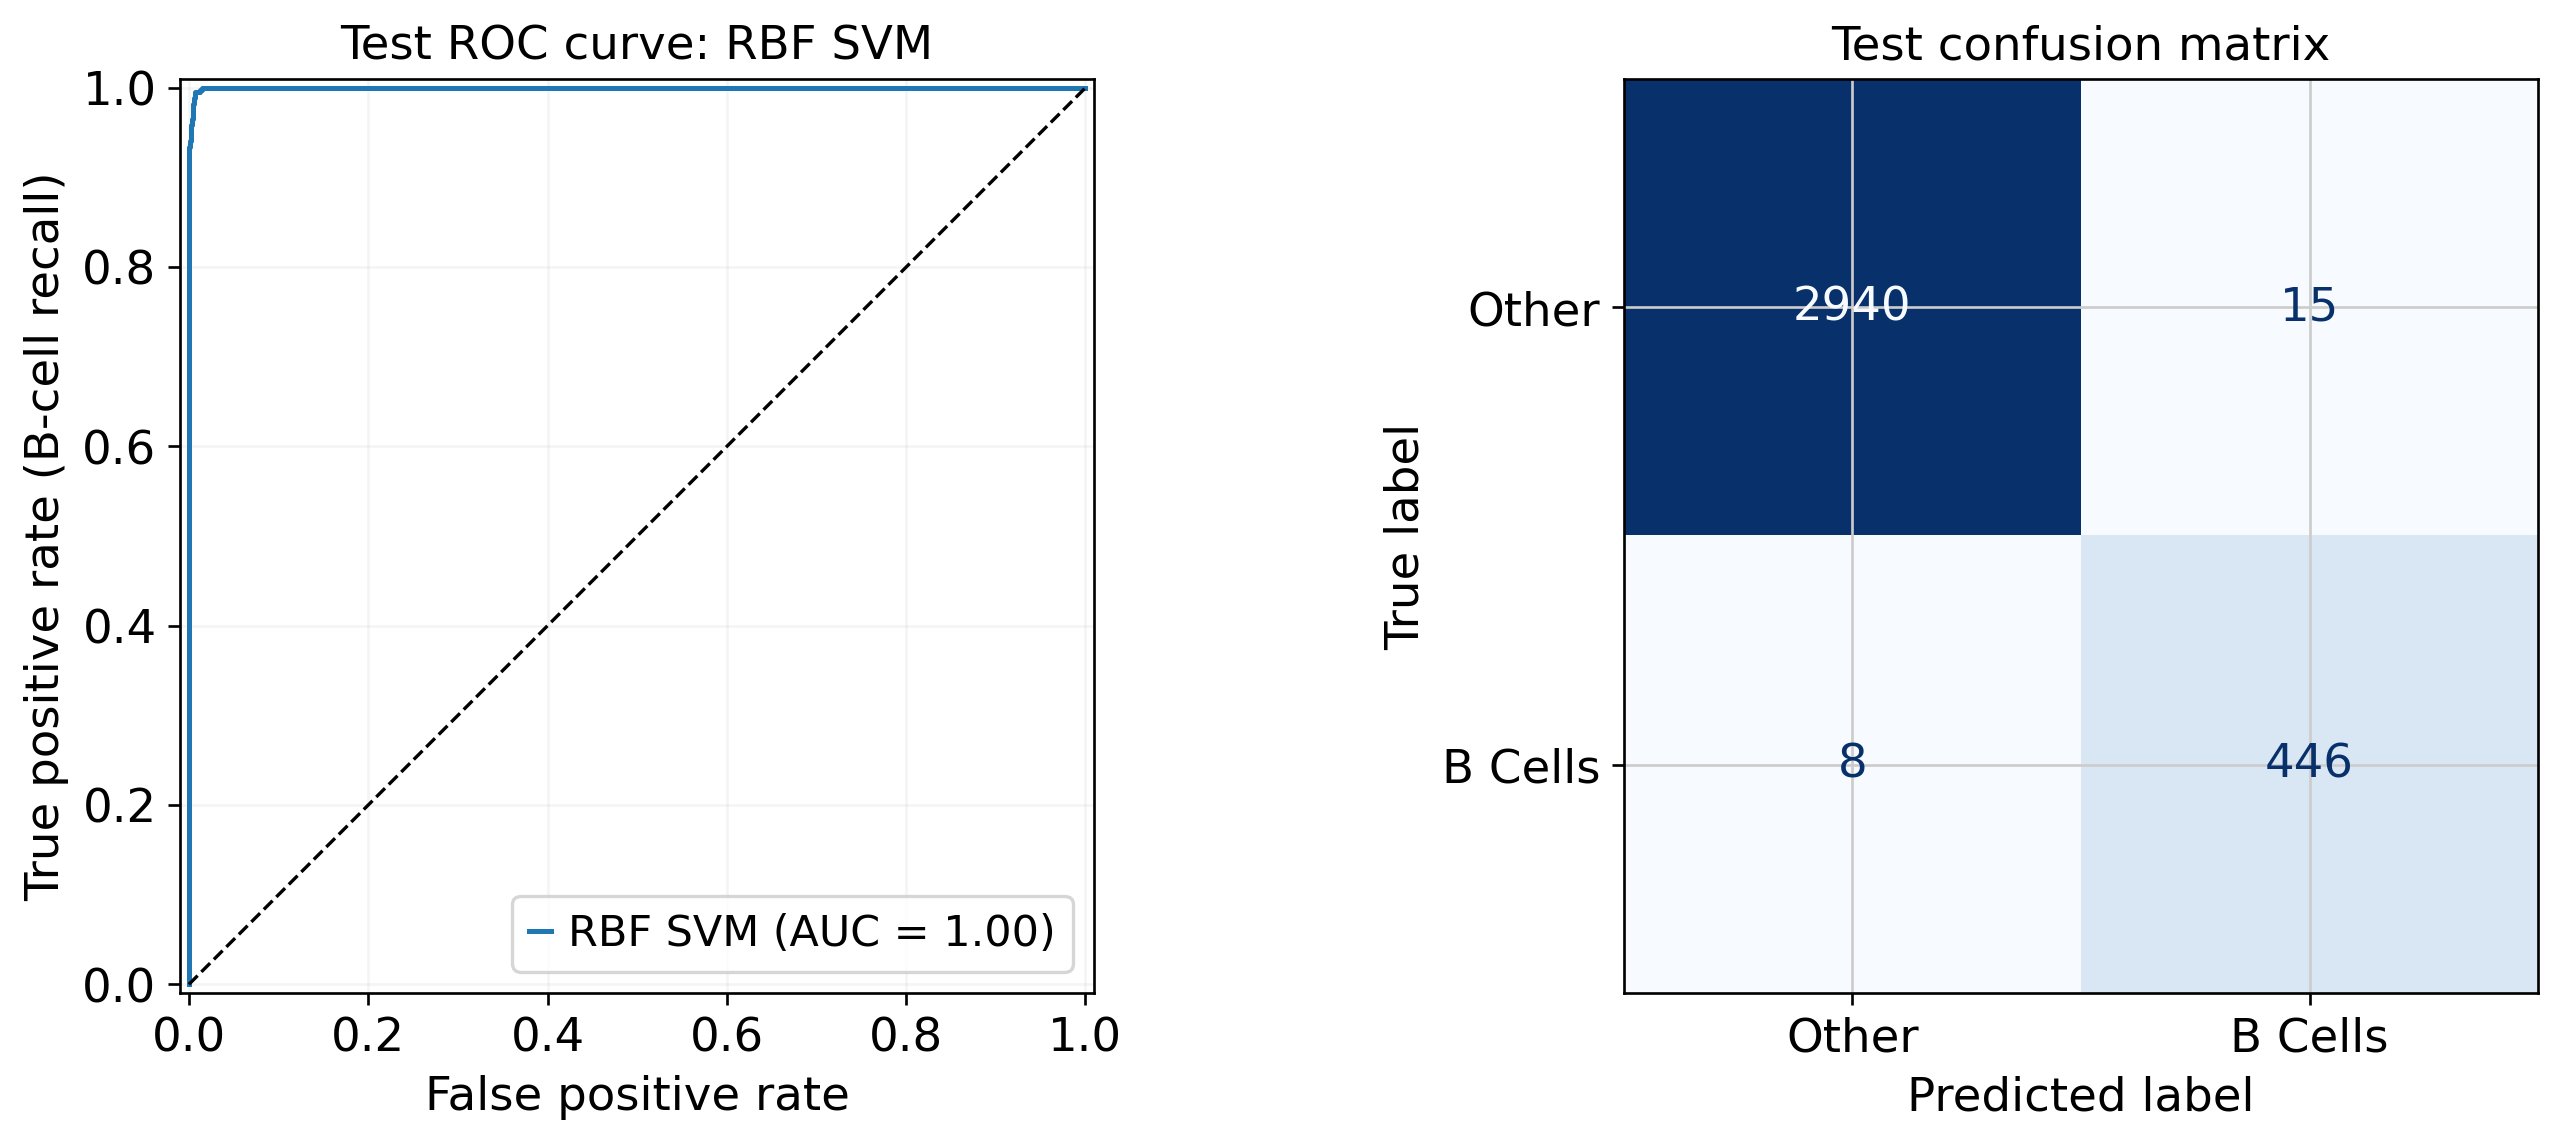

,cell_id,reference_label,predicted_label,positive_class_score,correct
0,ATTCCTAAGTCTGGTT-1,0,0,-3.123282,True
1,CCCGGAAGTCGAAACG-1,0,0,-1.761799,True
2,GTCCTCAGTGCAGGAT-1,0,0,-1.489165,True
3,GCTGAATGTCTTTCTA-1,0,0,-3.174368,True
4,GGGTCACTCGCATAGT-1,0,0,-1.702041,True


In [34]:
# Evaluate the selected model without further tuning or refitting.
test_scores = positive_scores(winner_model, X_test)
test_predictions = winner_model.predict(X_test)

test_ap = average_precision_score(y_test, test_scores)
test_auc = roc_auc_score(y_test, test_scores)

print(f"Final test evaluation: {winner_name}")
print(f"Test average precision: {test_ap:.4f}")
print(f"Test ROC-AUC:           {test_auc:.4f}")
print(f"Test B-cell prevalence: {y_test.mean():.4f}")
print("\nClassification report at the model's default threshold:\n")

print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["Other annotated cells", "B Cells"],
    digits=3,
    zero_division=0,
))

# Display the test ROC curve and confusion matrix.
fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=120)

RocCurveDisplay.from_predictions(
    y_test,
    test_scores,
    name=winner_name,
    ax=axes[0],
)
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[0].set(
    title=f"Test ROC curve: {winner_name}",
    xlabel="False positive rate",
    ylabel="True positive rate (B-cell recall)",
)
axes[0].grid(alpha=0.2)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=[0, 1],
    display_labels=["Other", "B Cells"],
    cmap="Blues",
    colorbar=False,
    values_format="d",
    ax=axes[1],
)
axes[1].set_title("Test confusion matrix")

plt.tight_layout()
plt.show()

# Link predictions back to the original cell identifiers.
test_results = pd.DataFrame({
    "cell_id": adata.obs_names[cell_indices[test_idx]].to_numpy(),
    "reference_label": y_test,
    "predicted_label": test_predictions,
    "positive_class_score": test_scores,
})
test_results["correct"] = (
    test_results["reference_label"] == test_results["predicted_label"]
)

display(test_results.head())

**## Exit questions**

### 1. Define the classification problem

What are the observations, predictor features, and target labels in this classification problem?

**Your response:** Each observation is one annotated cell from the two bone-marrow samples. The predictors are normalized, log-transformed gene-expression measurements calculated from the saved counts. Within each training fold, the pipeline removes constant genes and selects 500 genes associated with the training labels. The target labels are B Cells (1) and other annotated cells (0). These labels come from the tutorial’s clustering and marker-based annotations.

### 2. Establish a baseline

Using the training partition, calculate the accuracy of a classifier that predicts "Other" for every cell. What would its B-cell recall be? Why stratify the split?

**Your response:** The training partition contains 8,863 other cells and 1,361 B cells, for a total of 10,224 cells. Predicting “Other” for every cell would give an accuracy of 8,863 / 10,224, or approximately 86.69%. However, B-cell recall would be 0% because the classifier would miss every B cell. This shows why accuracy alone can be misleading when one class is much more common. Stratification keeps the B-cell proportion similar across training, validation, and test sets. In my split, B cells make up approximately 13.3% of each partition.

### 3. Identify the selected model

Which classifier was selected, and what were its best hyperparameters?

**Your response:** The selected classifier was RBF SVM with C=1.0 and gamma=0.001. Its hyperparameters were chosen using five-fold cross-validation within the training set. RBF SVM was then selected over the other classifier families because it had the highest validation average precision, 0.9986. Random Forest had validation average precision of 0.9977, and logistic regression had 0.9972. The test set was not used to choose the model.

### 4. Interpret what the classifier learned

What did the classifier learn to predict? How does this differ from independently establishing a cell's biological identity?

**Your response:** The classifier learned expression patterns that distinguish cells annotated as B cells from cells given other annotations in this dataset. These reference labels were assigned using clustering and known marker genes. In my analysis, low-resolution cluster 2 showed strong B-cell marker expression and was labeled “B Cells.” High agreement with these labels shows that the classifier can reproduce the annotation pattern. It does not independently establish biological identity because the labels themselves were inferred from the same expression dataset. Independent evidence, such as measured cell-surface proteins or experimentally sorted cells, would provide a stronger check.

### 5. Interpret classification errors

What would a false positive and a false negative mean in this analysis?

**Your response:** A false positive is a cell annotated as “Other” that the classifier predicts to be a B cell. A false negative is a cell annotated as a B cell that the classifier predicts to be “Other.” My test results contained 15 false positives and 8 false negatives. These errors are disagreements with the tutorial-derived reference labels. They do not automatically prove that the classifier is biologically wrong, because the reference annotations can also contain uncertainty or mistakes.

### 6. Evaluate the classifier

Is the selected classifier a good classifier for this task? Justify your answer using its test-set sensitivity, precision, specificity, and F1 score. Calculate specificity from the confusion matrix as TN / (TN + FP).

**Your response:** The selected classifier performed very well at reproducing the reference B-cell labels in this dataset. It correctly identified 446 of the 454 annotated B cells, giving sensitivity of 446 / (446 + 8) = 0.982, or about 98.2%. Precision was 446 / (446 + 15) = 0.967, or about 96.7%. Specificity was 2,940 / (2,940 + 15) = 0.9949, or about 99.49%. The B-cell F1 score was 0.975. Test average precision was 0.9978, and ROC-AUC was 0.9997. These results show few disagreements with the reference labels, but they do not establish equally strong performance on independently collected samples or prove the annotations are biologically correct.

### 7. Assess independence and leakage

The classifier's gene selection, scaling, and hyperparameter tuning use only training data. However, the tutorial generated the cell-type labels by clustering and annotating the full dataset before the split.

Is the test set fully independent of the complete analysis? Explain how test cells influenced the upstream analysis, what this means for interpreting high test accuracy, and what a stronger evaluation would require.

**Your response:** The test set is held out from classifier fitting and model selection, but it is not fully independent of the complete analysis. Before splitting, all cells contributed to the tutorial’s variable-gene selection, PCA, neighbor graph, clustering, and marker analysis used to assign the reference labels. This included cells later placed in the test set. The classifier pipeline correctly fits its own gene selection and scaling within the training folds, but that does not remove the dependence introduced when the labels were created. The high test accuracy therefore shows strong agreement with annotations derived from this shared dataset, rather than fully independent confirmation of cell identity. A stronger evaluation would use new donors or samples held out before the upstream analysis, with reference labels established independently. Keeping all cells from the same donor or sample together during splitting would also provide a better assessment of performance on new biological samples.